In [ ]:
# Install required libraries and import them
!pip install pywavelets opencv-python matplotlib numpy
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt
print("Setup complete!")

Setup complete!


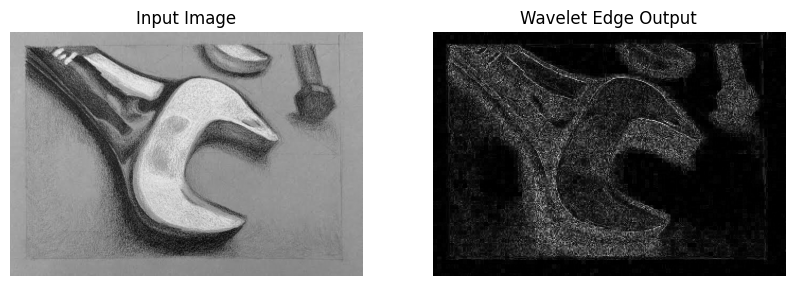

In [ ]:
# 1. Load an image or create a synthetic test shape if no image is uploaded
try:
    img = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError
except Exception:
    # Fallback synthetic white square on black background
    img = np.zeros((256, 256), dtype=np.float32)
    img[64:192, 64:192] = 255

# 2. Apply 2D Discrete Wavelet Transform using Haar wavelet
cA, (cH, cV, cD) = pywt.dwt2(img, 'haar')

# 3. Compute edge magnitude and normalize to 0-255
edge_mag = np.sqrt(cH**2 + cV**2 + cD**2)
edge_mag = cv2.normalize(edge_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 4. Display the input and output side-by-side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Input Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(edge_mag, cmap='gray')
plt.title("Wavelet Edge Output")
plt.axis('off')
plt.show()